# Tox21 Foundations: predict activity and propose molecules

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/CompOmics/ML_AI_Analytical_Chemistry_Course/blob/main/01_Foundations/notebooks/TD1_tox21_solution.ipynb)

A laboratory wants to prioritise compounds for follow-up tests. Can a small
decision tree use eight molecular properties to predict a recorded assay
result? This is classification: choosing between Active and Inactive.
We begin with one tree, then use a pretrained autoencoder to propose
related structures and predict their assay class. Evaluation will ask how
to compare prediction models.

All three Tox21 practicals use SR-MMP, an assay concerning
mitochondrial membrane potential. Active means a positive result
in this assay; Inactive means a negative result. Neither label is
an overall judgement about human toxicity or safety.

All code is supplied. Run the cells from top to bottom with their ▶ buttons.
Read the explanation above each cell and inspect its output. To answer a
question, double-click its Your answer text cell and write in words.

Click Open in Colab above to start this notebook. Use the standard CPU runtime.

Instructor copy: suggested answers are included.

## 1. Look at the compounds

Each sample is one compound record with a chemical structure and
assay results. A feature is a number describing that structure; the
recorded assay label is kept separate from the features.

First install RDKit, which reads structures, draws them and calculates
molecular properties. The version is fixed so the calculations stay consistent.

The installation cell also prepares the pretrained molecular autoencoder
used later. Run it before the import cells.

In [1]:
%pip -q install rdkit==2025.9.6
%pip -q install "jax[cpu]==0.11.2" flax==0.12.10 optax==0.2.8 orbax-checkpoint==0.11.32
%pip -q install --no-deps jax-cddd==0.1.0.post0

Load the tools: `pd` works with tables and `plt` draws plots.
`Chem` reads structures, `Draw` draws them and `Descriptors` calculates
their properties. The last line hides RDKit diagnostics; unreadable
structures are counted explicitly below.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from rdkit import Chem, RDLogger
from rdkit.Chem import Descriptors, Draw
from sklearn.model_selection import train_test_split

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
RDLogger.DisableLog("rdApp.*")

Read the public Tox21 file used by DeepChem. Each row is a compound record.
The file contains 12 assay columns; we use SR-MMP throughout the series.
`mol_id` identifies the source record and `smiles` describes its structure
as text. In SR-MMP, `1` means Active, `0` means Inactive and `NaN` means
no usable recorded result. Show these columns for the first five records.

In [3]:
DATA_URL = "https://deepchemdata.s3-us-west-1.amazonaws.com/datasets/tox21.csv.gz"
raw_data = pd.read_csv(DATA_URL)
print("Source records:", len(raw_data))
raw_data[["mol_id", "smiles", "SR-MMP"]].head()

Source records: 7831


,mol_id,smiles,SR-MMP
0,TOX3021,CCOc1ccc2nc(S(N)(=O)=O)sc2c1,0.0
1,TOX3020,CCN1C(=O)NC(c2ccccc2)C1=O,0.0
2,TOX3024,CC[C@]1(O)CC[C@H]2[C@@H]3CCC4=CCCC[C@@H]4[C@H]...,NaN
3,TOX3027,CCCN(CC)C(CC)C(=O)Nc1c(C)cccc1C,0.0
4,TOX20800,CC(O)(P(=O)(O)O)P(=O)(O)O,0.0


A missing result is unknown, not Inactive. `dropna` keeps records with
an SR-MMP result and a structure string, leaving 5,810 records.

In [4]:
data = raw_data.dropna(subset=["SR-MMP", "smiles"]).copy()
print("Records with a result and structure string:", len(data))

Records with a result and structure string: 5810


`map` applies the structure-reading tool to each string. RDKit cannot
read six structures in this labelled subset. Count them and leave them
out, keeping 5,804 records. `~` means “not”.

In [5]:
data["molecule"] = data["smiles"].map(Chem.MolFromSmiles)
readable = data["molecule"].notna()
print("Structures that could not be read:", (~readable).sum())
data = data.loc[readable].copy()
print("Records kept:", len(data))

Structures that could not be read: 6
Records kept: 5804


### Draw four example compounds

Draw the first four retained structures, with their source IDs underneath.
These are the structures represented by the SMILES strings in the table.
A drawing shows the recorded structure; it does not establish assay activity.
`molsPerRow=2` places two structures on each row.

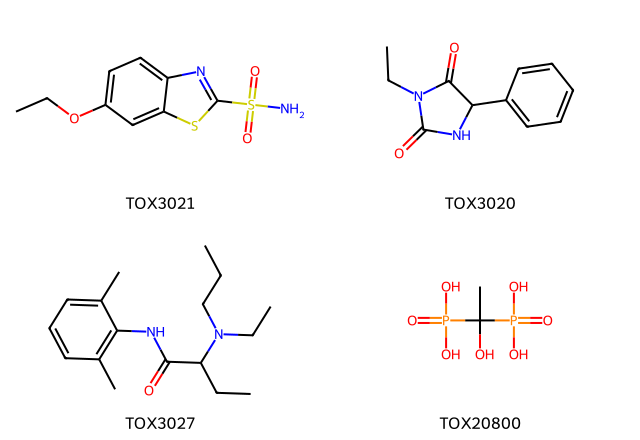

In [6]:
Draw.MolsToGridImage(
    data["molecule"].head(4).tolist(), molsPerRow=2,
    legends=data["mol_id"].head(4).tolist(), subImgSize=(320, 220)
)

## 2. Describe each compound with eight numbers

Calculate eight features from each retained structure. These descriptors
summarise properties such as size, hydrogen bonding and predicted
partitioning. The experimental SR-MMP result is kept separate.

| Feature | Meaning |
|---|---|
| Mass | Calculated molecular weight (g/mol) |
| LogP | Predicted octanol/water partition coefficient, on a log scale |
| H_donors | Number of hydrogen-bond donors |
| H_acceptors | Number of hydrogen-bond acceptors |
| Polar_area | Calculated topological polar surface area (Å²) |
| Rotatable_bonds | Number of rotatable bonds |
| Aromatic_rings | Number of aromatic rings |
| Heavy_atoms | Number of atoms other than hydrogen |

Each `map` below applies one named calculation to every molecule.
The same eight calculations are used throughout the Tox21 series.

In [7]:
features = pd.DataFrame(index=data.index)
features["Mass"] = data["molecule"].map(Descriptors.MolWt)
features["LogP"] = data["molecule"].map(Descriptors.MolLogP)
features["H_donors"] = data["molecule"].map(Descriptors.NumHDonors)
features["H_acceptors"] = data["molecule"].map(Descriptors.NumHAcceptors)
features["Polar_area"] = data["molecule"].map(Descriptors.TPSA)
features["Rotatable_bonds"] = data["molecule"].map(Descriptors.NumRotatableBonds)
features["Aromatic_rings"] = data["molecule"].map(Descriptors.NumAromaticRings)
features["Heavy_atoms"] = data["molecule"].map(Descriptors.HeavyAtomCount)

The reference label is the assay class recorded in the dataset. Replace
0 and 1 with their class names. The counts show that Inactive is much
more common than Active; we keep these unequal class sizes.

In [8]:
labels = data["SR-MMP"].map({0: "Inactive", 1: "Active"})
print(labels.value_counts())

SR-MMP
Inactive    4886
Active       918
Name: count, dtype: int64


Show the source ID, eight features and reference label for the first
five retained records. The first four correspond to the drawings above.
`round(2)` rounds only this preview. The models use the unrounded eight
columns in `features`; IDs and labels are not added to their inputs.

In [9]:
preview = features.head().round(2)
preview.insert(0, "Source ID", data["mol_id"].head())
preview["Reference label"] = labels.head()
preview

,Source ID,Mass,LogP,H_donors,H_acceptors,Polar_area,Rotatable_bonds,Aromatic_rings,Heavy_atoms,Reference label
0,TOX3021,258.32,1.34,1,5,82.28,3,2,16,Inactive
1,TOX3020,204.23,1.30,1,2,49.41,2,1,15,Inactive
3,TOX3027,276.42,3.75,1,2,32.34,7,1,20,Inactive
4,TOX20800,206.03,-0.99,5,3,135.29,2,0,11,Inactive
5,TOX5110,290.44,4.82,0,4,36.92,7,0,20,Inactive


### Plot two of the eight features

Each dot is a retained compound, coloured by its recorded assay label.
The axes show Mass and LogP; the models receive all eight features.
The classes can overlap in this view. There are more Inactive records,
so the numbers of dots also reflect the unequal class sizes.

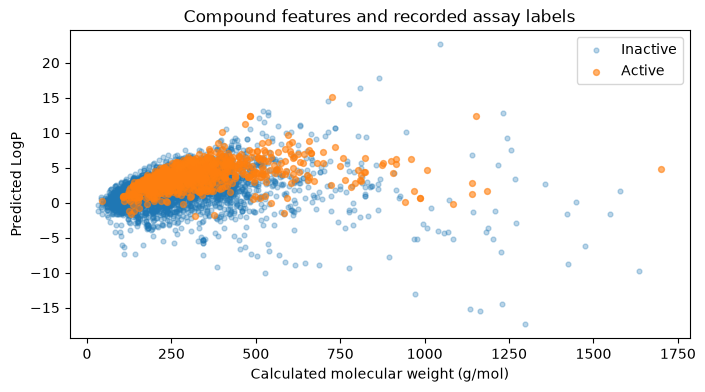

In [10]:
inactive = labels == "Inactive"
active = labels == "Active"
plt.figure(figsize=(8, 4))
plt.scatter(features.loc[inactive, "Mass"], features.loc[inactive, "LogP"], label="Inactive", alpha=0.3, s=12)
plt.scatter(features.loc[active, "Mass"], features.loc[active, "LogP"], label="Active", alpha=0.6, s=18)
plt.xlabel("Calculated molecular weight (g/mol)")
plt.ylabel("Predicted LogP")
plt.title("Compound features and recorded assay labels")
plt.legend()
plt.show()

### Stop and explain 1

What are the inputs, and which assay result should the model predict?
Is LogP a measured toxicity result? Why must a missing assay result be left out?

Suggested answer: The inputs are eight calculated molecular descriptors;
the target is Active or Inactive for SR-MMP. LogP is a predicted partition
property, not a toxicity measurement. A missing assay result is unknown,
so assigning it Inactive would invent a reference label.

## 3. Keep some compounds for testing

Training samples teach the model; test samples check predictions
on records excluded from training. In the code, X means features and
y means labels. The endings `_train` and `_test` name the sample groups.

Keep 80% for training and 20% for testing: 4,643 and 1,161 records.
`stratify=labels` keeps similar class proportions. `random_state=42` makes
the split repeatable. Keep these settings unchanged throughout the series.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    features, labels, test_size=0.20, random_state=42, stratify=labels
)
print("Training samples:", len(X_train))
print("Test samples:", len(X_test))

Training samples: 4643
Test samples: 1161


### Stop and explain 2

Why do we test on compounds excluded from training? Does a random split
guarantee that the test compounds come from different chemical families?

Suggested answer: Testing excluded records checks whether the learned
rules work beyond the training examples. A random split can place related
compounds in both groups; it does not prove performance on new chemical families.

## 4. Teach one small tree

A tree asks questions about features and ends with a class prediction.
`max_depth=2` allows at most two questions along a path. `fit` learns from
the training features and their reference labels, without using test samples.

Active results are less common. `class_weight="balanced"` gives the two
classes equal total influence during training. This fixed setting does
not change the number of records in either class.

In [12]:
tree = DecisionTreeClassifier(
    max_depth=2, class_weight="balanced", random_state=42
)
tree.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",2
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: dict, list of dict or ""balanced"", default=NoneWeights associated with classes in the form ``{class_label: weight}``.If None, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_feat

Read from the top: a true condition follows the left branch; a false
condition follows the right. The `class` line gives a prediction.
`samples` counts training records. The `value` numbers include the
class-balancing weights; focus on the feature rules and `class` lines.

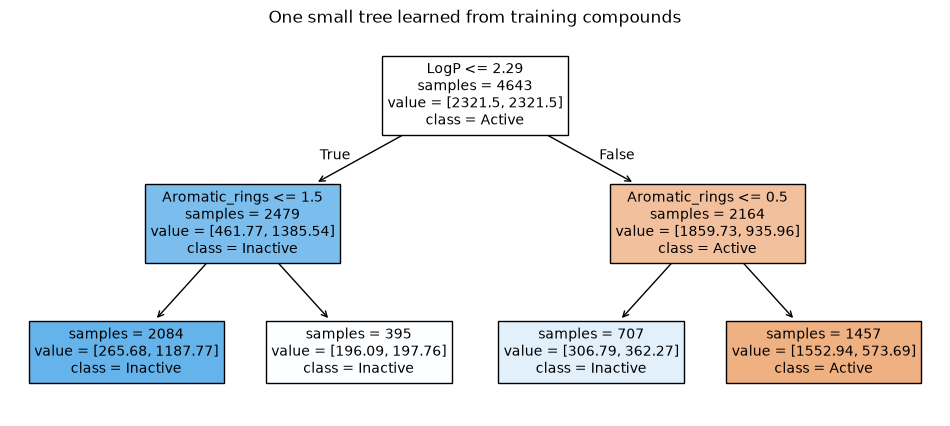

In [13]:
plt.figure(figsize=(12, 5))
plot_tree(tree, feature_names=features.columns, class_names=tree.classes_,
          filled=True, impurity=False, precision=2, fontsize=10)
plt.title("One small tree learned from training compounds")
plt.show()

### Stop and explain 3

Which feature appears in the first question, and which branch does a
smaller value follow? Find one path ending in Active. Does this path prove toxicity?

Suggested answer for the saved run: The first question uses LogP
at about 2.29. A value at or below that threshold follows
the left branch. One Active path is: LogP > 2.29 and Aromatic_rings > 0.50.
This is a rule learned from one assay dataset, not proof of human toxicity.

## 5. Apply the rules and read accuracy

`predict` applies the fixed tree to the test features. The table shows
predictions beside the known test labels; the labels did not teach the tree.

In [14]:
predictions = tree.predict(X_test)
prediction_table = pd.DataFrame({"Reference": y_test, "Prediction": predictions})
prediction_table.head()

,Reference,Prediction
4867,Inactive,Inactive
6532,Inactive,Inactive
924,Inactive,Inactive
3012,Active,Active
5043,Inactive,Inactive


Accuracy is the fraction of predictions matching their reference labels.
A score of 0.90 means 90% correct. Compare the tree with a rule that always
predicts Inactive, the most common training class. `==` checks whether
each label is Inactive; `mean()` gives the fraction of matches.

In [15]:
tree_accuracy = accuracy_score(y_test, predictions)
baseline_accuracy = (y_test == "Inactive").mean()
print("Always predict Inactive:", round(baseline_accuracy, 3))
print("Small decision tree:", round(tree_accuracy, 3))

Always predict Inactive: 0.842
Small decision tree: 0.739


### Stop and explain 4

Quote both accuracies. If we always predict Inactive, how many Active
compounds can we detect? Why can a high accuracy be misleading here?

Suggested answer for the saved run: The tree has 73.9% accuracy;
always predicting Inactive gives 84.2%. The constant rule finds no
Active compounds. Because most records are Inactive, a high overall score
can hide missed Active compounds. We need the mistake counts as well.

## 6. Look at both kinds of mistake

In this confusion matrix, rows show reference labels and columns show
predictions. The diagonal contains correct predictions. An Active compound
predicted Inactive is a missed Active result (false negative). An
Inactive compound predicted Active is a false alarm (false positive).

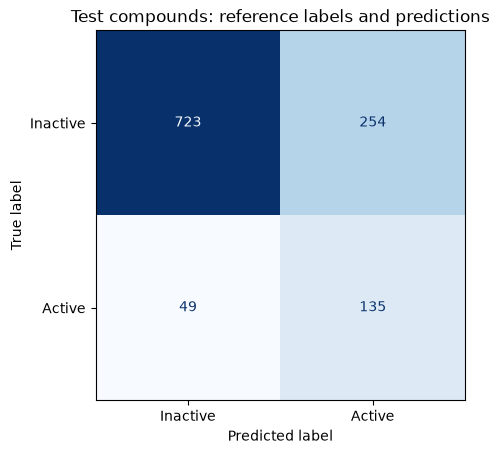

In [16]:
ConfusionMatrixDisplay.from_predictions(
    y_test, predictions, labels=["Inactive", "Active"],
    cmap="Blues", colorbar=False
)
plt.title("Test compounds: reference labels and predictions")
plt.show()

### Stop and explain 5

How many Active results were missed, and how many false alarms occurred?
Give one consequence of each when planning follow-up experiments.

Suggested answer for the saved run: There are 49 missed
Active results and 254 false alarms. Missing an Active compound
can remove an interesting assay response from follow-up priorities. A false
alarm can use laboratory time on a compound recorded Inactive in this assay.

## 7. Explain the result

The tree predicts this assay's recorded classes from calculated descriptors.
It does not identify a toxic mechanism or establish human safety. Related
compounds can occur on both sides of our random split.

Next, Evaluation keeps the same features and test group but sets aside
some training records to help choose between models.

### Stop and explain 6

Write three sentences for the laboratory manager: what the tree predicts,
what its mistakes show, and one limitation before using it on new compounds.

Example: The tree predicts SR-MMP Active or Inactive from eight calculated
molecular descriptors. It missed 49 Active test results and
produced 254 false alarms, so accuracy alone is insufficient.
We need further validation on new chemical families, and an assay prediction
cannot certify human safety.

## 8. Reconstruct a molecule

So far, a model has predicted an assay label from a structure. Now we
use a different neural network to propose structures. An autoencoder
has two parts: an encoder turns a molecule into learned numbers, and
a decoder turns those numbers back into a molecular structure.

Molecule → encoder → learned numbers → decoder → molecule

We load CDDD, a pretrained molecular autoencoder. Its training task
was to translate different SMILES descriptions of the same structure.
SMILES is a text representation of atoms and bonds. CDDD learned from
a large collection of structures; we do not train it in this notebook.
It does not use our SR-MMP labels. The first run downloads its weights.

This is the encode–change–decode idea used in molecular design.
CDDD is a translation autoencoder, rather than the variational
autoencoder in the Gómez-Bombarelli example cited below.
The supplied settings work with a CPU runtime.

In [17]:
import numpy as np
from rdkit import DataStructs
from jax_cddd.inference import CDDDModel

autoencoder = CDDDModel(warmup=False)

Our starting molecule is aspirin, source record TOX108. It belongs to
the training group from earlier, so we do not choose it using test
results. The table shows its recorded assay result. We pass only its
structure to the autoencoder.

In [18]:
seed_row = data.loc[data["mol_id"].eq("TOX108")].iloc[0]
seed_molecule = seed_row["molecule"]
seed_smiles = Chem.MolToSmiles(seed_molecule)
print("Starting molecule:", seed_row["mol_id"], "(aspirin)")
print("In the training group:", seed_row.name in X_train.index)
print("Recorded SR-MMP result:", labels.loc[seed_row.name])

Starting molecule: TOX108 (aspirin)
In the training group: True
Recorded SR-MMP result: Inactive


The encoder produces 512 learned numbers, together called a latent
representation. These are different from our eight named descriptors:
an individual latent number does not have a simple meaning such as
molecular weight. We ask the decoder to reconstruct the structure
without changing these numbers.

In [19]:
latent = autoencoder.seq_to_emb(seed_smiles)
reconstructed_smiles = autoencoder.emb_to_seq(latent, beam_width=5, max_len=120)
reconstructed_molecule = Chem.MolFromSmiles(reconstructed_smiles)
print("Number of learned values:", latent.size)
print("Starting SMILES:", seed_smiles)
print("Reconstructed SMILES:", reconstructed_smiles)
print("Same structure:", Chem.MolToSmiles(reconstructed_molecule) == seed_smiles)

Number of learned values: 512
Starting SMILES: CC(=O)Oc1ccccc1C(=O)O
Reconstructed SMILES: CC(=O)Oc1ccccc1C(=O)O
Same structure: True


Compare the starting and reconstructed structures. Different SMILES
text can describe the same molecule. The comparison above uses RDKit's
canonical SMILES, a consistent ordering for the structure description.

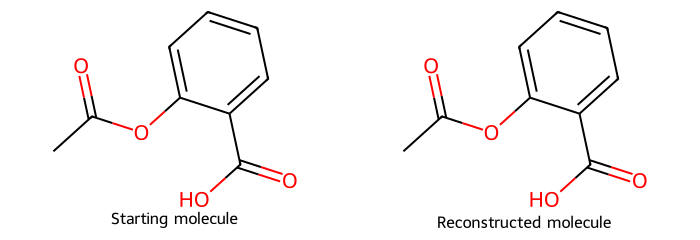

In [20]:
Draw.MolsToGridImage(
    [seed_molecule, reconstructed_molecule], molsPerRow=2,
    legends=["Starting molecule", "Reconstructed molecule"],
    subImgSize=(350, 240))

### Stop and explain 7

Did the decoder reconstruct the starting structure? What do the 512
numbers represent, and how do they differ from the eight descriptors?
Does a correct reconstruction tell us anything about SR-MMP activity?

Suggested answer for the saved run: Yes, the canonical structures match.
The 512 numbers are a representation learned from molecular structures;
unlike Mass or LogP, they are not individually named chemical properties.
Reconstruction checks whether information about the structure survives
encoding and decoding. It does not test an assay prediction, and no
SR-MMP label was supplied to the autoencoder.

## 9. Propose nearby structures

We make twelve randomly changed copies of the latent representation
and decode them. The random seed makes this demonstration repeatable.
The value 0.6 sets the size of the random changes; it is a teaching
setting, not a chemical unit or a guarantee of structural similarity.
The decoder may return the starting molecule, a changed structure,
or text that does not describe a valid molecule.

In [21]:
random = np.random.default_rng(42)
nearby_latents = latent + random.normal(0, 0.6, size=(12, 512))
decoded = autoencoder.emb_to_seq(nearby_latents, beam_width=5, max_len=120)
attempts = pd.DataFrame({"Decoded SMILES": decoded})
attempts["molecule"] = attempts["Decoded SMILES"].map(Chem.MolFromSmiles)

RDKit checks whether each proposed string can be read as a structure.
We count invalid outputs before removing them. Passing this check does
not establish that a molecule is stable or can be synthesised.

In [22]:
valid = attempts.loc[attempts["molecule"].notna()].copy()
valid["SMILES"] = valid["molecule"].map(Chem.MolToSmiles)
print("Decoding attempts:", len(attempts))
print("Invalid outputs:", len(attempts) - len(valid))
print("Valid outputs equal to the starting molecule:", valid["SMILES"].eq(seed_smiles).sum())
print("Distinct valid structures, including the start if returned:", valid["SMILES"].nunique())

Decoding attempts: 12
Invalid outputs: 1
Valid outputs equal to the starting molecule: 4
Distinct valid structures, including the start if returned: 8


We keep each changed structure once and give it a candidate number.
The starting molecule is added separately for comparison. This avoids
counting repeated reconstructions as different proposals.

In [23]:
candidates = valid.drop_duplicates("SMILES")
candidates = candidates.loc[candidates["SMILES"].ne(seed_smiles)].copy()
candidates.index = "Candidate " + (pd.RangeIndex(len(candidates)) + 1).astype(str)
start = pd.DataFrame({"SMILES": [seed_smiles], "molecule": [seed_molecule]},
                     index=["Starting molecule"])
proposed = pd.concat([start, candidates[["SMILES", "molecule"]]])
print("Distinct changed candidates:", len(candidates))

Distinct changed candidates: 7


Are these structures already in Tox21? We compare canonical structures
with all readable structures in the downloaded file, including records
without an SR-MMP result. Absence from this file does not establish
novelty in science, or absence from the autoencoder's training data.

We also compare molecular fingerprints: summaries of structural
patterns. Their Tanimoto similarity ranges from 0 to 1; larger values
mean more shared fingerprint patterns. A score of 1 does not prove
identical structures, and similarity does not guarantee equal activity.

In [24]:
known_structures = raw_data["smiles"].dropna().map(Chem.MolFromSmiles).dropna().map(Chem.MolToSmiles)
fingerprints = proposed["molecule"].map(Chem.RDKFingerprint)
proposed["In Tox21 file"] = proposed["SMILES"].isin(known_structures)
proposed["Similarity to start"] = DataStructs.BulkTanimotoSimilarity(
    Chem.RDKFingerprint(seed_molecule), fingerprints.tolist())
proposed[["SMILES", "In Tox21 file", "Similarity to start"]].round(2)

,SMILES,In Tox21 file,Similarity to start
Starting molecule,CC(=O)Oc1ccccc1C(=O)O,True,1.00
Candidate 1,C[PH](=O)Oc1ccccc1C(N)O,False,0.27
Candidate 2,CC(=O)OCc1ccccc1C(C)C,False,0.20
Candidate 3,CC(=O)OCCc1ccccc1C(=O)O,False,0.25
Candidate 4,CC(=O)Oc1ccccc1C(=O)C(=O)O,False,0.49
Candidate 5,CC(=O)Oc1ccccc1O,False,0.31
Candidate 6,CC(=O)Oc1ccccc1P(C)(=O)O,False,0.25
Candidate 7,CC(=O)c1ccccc1COC=O,False,0.22


Look at the structures as well as the similarity values. Use the
candidate numbers to connect this picture with the table above.

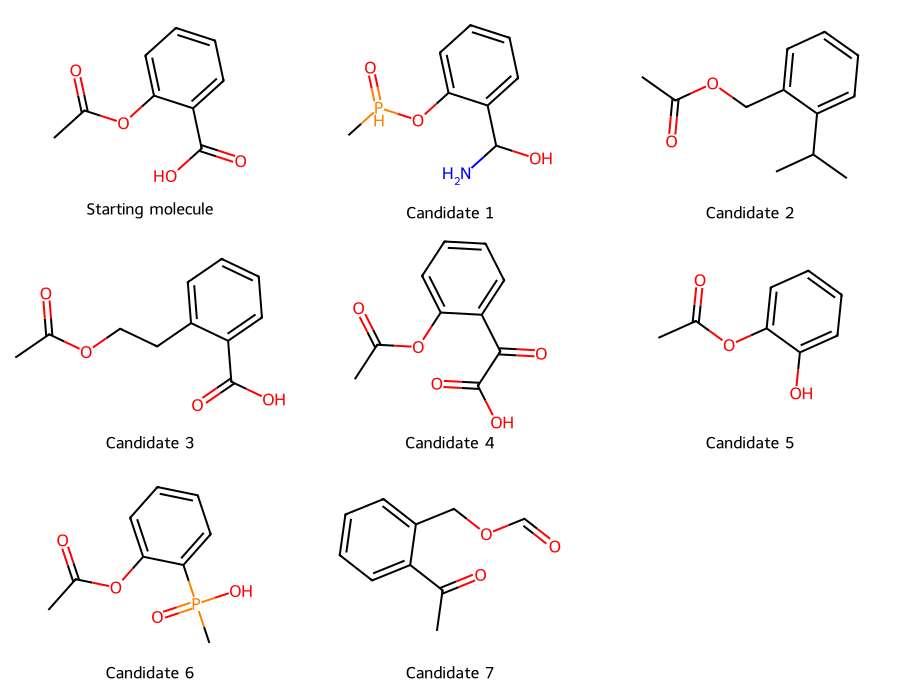

In [25]:
Draw.MolsToGridImage(
    proposed["molecule"].tolist(), molsPerRow=3,
    legends=proposed.index.tolist(), subImgSize=(300, 230))

### Stop and explain 8

How many attempts produced invalid output, and how many distinct changed
candidates remain? Choose one candidate and describe a structural change.
If it is absent from Tox21, can we call it a newly discovered molecule?

Suggested answer for the saved run: Twelve attempts produce one invalid
output, four copies of aspirin and seven distinct changed candidates.
For example, Candidate 2 changes the substituents around the aromatic
ring, while Candidate 3 inserts carbon atoms between the ring and an
ester group. Check the drawn bonds rather than assuming all changes are
small. Absence from the downloaded Tox21 file only establishes absence
from that reference under this canonical-structure comparison. The
candidate may be known elsewhere or present in pretraining. A readable
structure alone does not establish novelty or practical synthesis.

## 10. Predict assay activity for the candidates

We can apply the small tree from earlier to these structures. The tree
still requires the same eight descriptors in the same order. The latent
representation belongs to the generator and is not an input to this tree.
We calculate the descriptors exactly as we did for the training compounds.

In [26]:
new_features = pd.DataFrame(index=proposed.index)
new_features["Mass"] = proposed["molecule"].map(Descriptors.MolWt)
new_features["LogP"] = proposed["molecule"].map(Descriptors.MolLogP)
new_features["H_donors"] = proposed["molecule"].map(Descriptors.NumHDonors)
new_features["H_acceptors"] = proposed["molecule"].map(Descriptors.NumHAcceptors)
new_features["Polar_area"] = proposed["molecule"].map(Descriptors.TPSA)
new_features["Rotatable_bonds"] = proposed["molecule"].map(Descriptors.NumRotatableBonds)
new_features["Aromatic_rings"] = proposed["molecule"].map(Descriptors.NumAromaticRings)
new_features["Heavy_atoms"] = proposed["molecule"].map(Descriptors.HeavyAtomCount)

The table gives the tree's predicted SR-MMP class for the starting
molecule and each candidate. There is no measured reference label for
the generated candidates here, so we cannot calculate their accuracy.
The starting molecule's measured label was printed in section 8.

These predictions use the same tree whose test mistakes we inspected
earlier. They are screening hypotheses, not overall toxicity or safety
judgements. The autoencoder proposes structures without seeking a
particular assay result; the tree is a separate model.

In [27]:
candidate_results = new_features.round(2)
candidate_results["Predicted SR-MMP"] = tree.predict(new_features[features.columns])
candidate_results

,Mass,LogP,H_donors,H_acceptors,Polar_area,Rotatable_bonds,Aromatic_rings,Heavy_atoms,Predicted SR-MMP
Starting molecule,180.16,1.31,1,3,63.60,2,1,13,Inactive
Candidate 1,201.16,1.12,2,4,72.55,3,1,13,Inactive
Candidate 2,192.26,2.87,0,2,26.30,3,1,14,Active
Candidate 3,208.21,1.49,1,3,63.60,4,1,15,Inactive
Candidate 4,208.17,0.88,1,4,80.67,3,1,15,Inactive
Candidate 5,152.15,1.32,1,3,46.53,1,1,11,Inactive
Candidate 6,214.16,1.14,1,3,63.60,2,1,14,Inactive
Candidate 7,178.19,1.56,0,3,43.37,4,1,13,Inactive


This plot places the proposals beside the tree's training compounds
using two familiar descriptors. Overlap in this picture does not show
that every structural pattern is represented in training, or validate
predictions for a new chemical family.

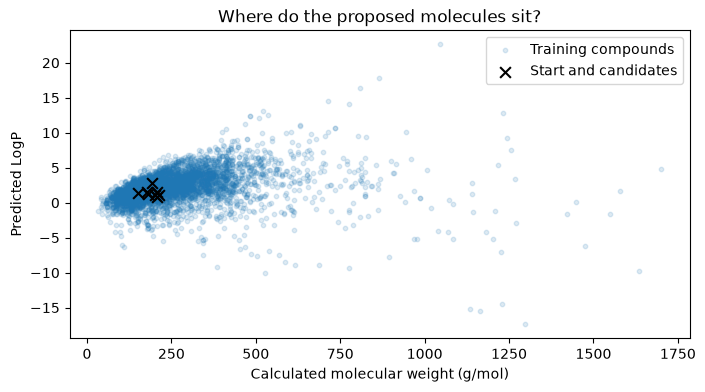

In [28]:
plt.figure(figsize=(8, 4))
plt.scatter(X_train["Mass"], X_train["LogP"], s=10, alpha=0.15, label="Training compounds")
plt.scatter(new_features["Mass"], new_features["LogP"], s=60, marker="x", color="black", label="Start and candidates")
plt.xlabel("Calculated molecular weight (g/mol)")
plt.ylabel("Predicted LogP")
plt.title("Where do the proposed molecules sit?")
plt.legend()
plt.show()

### Stop and explain 9

Choose a candidate and report its predicted SR-MMP class. Use the tree
picture to explain its prediction. Is this a measured result? Explain why structural similarity or an Inactive
prediction cannot establish safety. What would you need to check the
candidate's assay prediction?

Suggested answer for the saved run: Candidate 2 is predicted Active;
the other six candidates and aspirin are predicted Inactive. Candidate 2
has LogP 2.87 and one aromatic ring, following the Active branch in the
tree picture. This explains the model rule, not a biological mechanism.
The label is a prediction by the same small tree, not a newly
measured SR-MMP result. Similar structures can have different assay
responses, and the tree uses only eight descriptors. Its test errors
remain relevant, while performance on these proposed structures is
unknown. Inactive concerns one assay and cannot establish overall
safety. Checking a candidate requires an appropriate experimental
SR-MMP measurement; broader toxicity claims require other evidence.
Also consider whether the structure is chemically plausible and can
be prepared. Evaluation will compare models; Applications will examine
unusual descriptor patterns. Neither provides a substitute for a
measurement on the candidate.

## Data and reuse

These practicals use the public DeepChem Tox21 CSV, not a new experimental
dataset. Of 7,831 source records, 2,021 have no SR-MMP result and six more
have structures unreadable with the fixed RDKit version. The 5,804 retained
records contain 4,886 Inactive and 918 Active results. Instructors checked
that no identical canonical structure is repeated in this retained subset.
Different structures can still have identical values for these eight descriptors.

These random teaching splits are not DeepChem's default scaffold split:
related chemical families can occur in both training and test groups.
They do not establish performance on unfamiliar chemical families. No
fragments, charges or salts are removed from the recorded structures.

- [Tox21 challenge: assay tasks and original data context](https://tripod.nih.gov/tox21/challenge/about.jsp).
- [DeepChem Tox21 loader and source-file address](https://github.com/deepchem/deepchem/blob/master/deepchem/molnet/load_function/tox21_datasets.py).
- [RDKit molecular descriptor documentation](https://www.rdkit.org/docs/GettingStartedInPython.html#list-of-available-descriptors).

We read DeepChem's public data file directly with pandas and calculate
descriptors with RDKit. Installing the DeepChem Python package is not
required. These exercises do not reproduce the Tox21 challenge benchmark.
An assay prediction or an outlier flag cannot certify human safety.

The generation section uses the original pretrained CDDD default model,
accessed through jax-cddd 0.1.0.post0. Its weights are downloaded from
the publisher's release and checked by the package against its expected
SHA-256. CDDD translates equivalent structure representations; it is
not trained on our SR-MMP labels. Pretraining may overlap Tox21.
We use aspirin (TOX108) from the training group as a simple example.
Generated candidates do not enter training or test accuracy calculations.
Canonical-SMILES comparisons do not merge salts, tautomers or other
related forms into one identity. The random changes and decoding limits
are fixed teaching choices, not settings optimised for activity.

- [Winter et al., Chemical Science (2019): CDDD paper](https://doi.org/10.1039/C8SC04175J).
- [Original CDDD code and pretrained model](https://github.com/jrwnter/cddd).
- [JAX inference implementation and installation](https://pypi.org/project/jax-cddd/0.1.0.post0/).
- [Converted pretrained weights and vocabulary](https://github.com/OlivierBeq/jax-cddd/releases/tag/model_weights).
- [Gómez-Bombarelli et al., ACS Central Science (2018): molecular design with a variational autoencoder](https://doi.org/10.1021/acscentsci.7b00572).

The Gómez-Bombarelli paper motivates the general idea; this practical
uses a different pretrained model and does not reproduce that study.